# Programming Exercises - Chapter 10

**Stijn Lievens and Simon De Gheselle**  
June 26, 2026

This notebook contains the exercises from *Programming Exercises Chapter 10*. The text has been divided into coherent sections, and the supplied examples have been placed in code cells.


In [134]:
import keras
import numpy as np

## Contents

1. [Classification of the Iris Dataset with an MLP](#1-classification-of-the-iris-dataset-with-an-mlp)
2. [Binary Classification with an MLP](#2-binary-classification-with-an-mlp)
3. [MNIST with a Deep MLP](#3-mnist-with-a-deep-mlp)


# 1. Classification of the Iris Dataset with an MLP

In this exercise, we will build a small, very simple MLP to classify irises into 3 different species based on 4 measurements. We will keep this exercise very simple. Some things do not represent best practices.


## 1.1 Load the Data

The Iris dataset is built into `sklearn.datasets`. We use `return_X_y=True` to get a NumPy array with the features and a NumPy array with the targets.

Check the shape of these arrays. They should be `(150, 4)` and `(150,)`.


In [135]:
from sklearn.datasets import load_iris

X, y = load_iris(return_X_y=True)

print(X.shape, y.shape)
print(X)


(150, 4) (150,)
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]
 [5.4 3.7 1.5 0.2]
 [4.8 3.4 1.6 0.2]
 [4.8 3.  1.4 0.1]
 [4.3 3.  1.1 0.1]
 [5.8 4.  1.2 0.2]
 [5.7 4.4 1.5 0.4]
 [5.4 3.9 1.3 0.4]
 [5.1 3.5 1.4 0.3]
 [5.7 3.8 1.7 0.3]
 [5.1 3.8 1.5 0.3]
 [5.4 3.4 1.7 0.2]
 [5.1 3.7 1.5 0.4]
 [4.6 3.6 1.  0.2]
 [5.1 3.3 1.7 0.5]
 [4.8 3.4 1.9 0.2]
 [5.  3.  1.6 0.2]
 [5.  3.4 1.6 0.4]
 [5.2 3.5 1.5 0.2]
 [5.2 3.4 1.4 0.2]
 [4.7 3.2 1.6 0.2]
 [4.8 3.1 1.6 0.2]
 [5.4 3.4 1.5 0.4]
 [5.2 4.1 1.5 0.1]
 [5.5 4.2 1.4 0.2]
 [4.9 3.1 1.5 0.2]
 [5.  3.2 1.2 0.2]
 [5.5 3.5 1.3 0.2]
 [4.9 3.6 1.4 0.1]
 [4.4 3.  1.3 0.2]
 [5.1 3.4 1.5 0.2]
 [5.  3.5 1.3 0.3]
 [4.5 2.3 1.3 0.3]
 [4.4 3.2 1.3 0.2]
 [5.  3.5 1.6 0.6]
 [5.1 3.8 1.9 0.4]
 [4.8 3.  1.4 0.3]
 [5.1 3.8 1.6 0.2]
 [4.6 3.2 1.4 0.2]
 [5.3 3.7 1.5 0.2]
 [5.  3.3 1.4 0.2]
 [7.  3.2 4.7 1.4]
 [6.4 3.2 4.5 1

## 1.2 Build an MLP

We want to build an MLP consisting of:

- An input layer with the correct number of neurons. The name of the layer is `input`. How many neurons do we need in the input layer? 
*-> as many neurons as features of the input data. this means 4 in this case*
- One hidden layer with 5 neurons using the ReLU activation function. The name of the layer is `hidden`.
- One output layer with the correct number of neurons and the correct activation function for a classification problem. The name of the layer is `output`.


### Steps

1. Take a look at the examples in the [Keras Sequential model documentation](https://keras.io/api/models/sequential/).
2. See the [Keras activation documentation](https://keras.io/api/layers/activations/) for an example of passing an activation function via its string identifier.
3. Write similar code to create the model.
4. It is often convenient to recreate a model using a small function named `get_model`. Rewrite the previous code as a function `get_model` that returns the model described above. See the [Sequential class example](https://keras.io/api/models/model/#with-the-sequential-class).
5. Create the model using `get_model`.
6. Use the model's `summary` method to verify that the model has 43 parameters.
7. Convince yourself that you understand where this number comes from. Making a simple sketch of the model can be useful.


In [136]:
import keras

def get_model():
  model = keras.Sequential()
  model.add(keras.Input(shape=(4,), name="input"))
  model.add(keras.layers.Dense(5,activation="relu",name="hidden"))
  model.add(keras.layers.Dense(3,activation="softmax", name="output"))
  return model

model = get_model()
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden (Dense)                  │ (None, 5)              │            25 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 3)              │            18 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43 (172.00 B)

 Trainable params: 43 (172.00 B)

 Non-trainable params: 0 (0.00 B)

## 1.3 Compile the Model

Compile the model with the following options. See the [Keras model training API](https://keras.io/api/models/model_training_apis/).

- Use stochastic gradient descent with all default parameters as the optimizer.
- Specify the correct loss for a multi-class classification problem in which each instance belongs to exactly one class. Take into account that the targets have shape `(150,)`.
- Track the accuracy metric.


In [137]:
model.compile(
  optimizer="sgd",
  loss=keras.losses.sparse_categorical_crossentropy,
  metrics=("accuracy",)
)

## 1.4 Train the Model

Train the model for 20 epochs. Because we have such a small dataset, use a batch size of 8 so that there is a reasonable number of updates per epoch.

> **Note:** Since we are not using validation data, we have no way of knowing whether the model is overfitting. Do not do this in practice.


In [138]:
model.fit(
  x=X,
  y=y,
  batch_size=8,
  epochs=20
)


Epoch 1/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 675us/step - accuracy: 0.5267 - loss: 0.9984
Epoch 2/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.4333 - loss: 0.9081
Epoch 3/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.4467 - loss: 0.8554 
Epoch 4/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5333 - loss: 0.8392 
Epoch 5/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6267 - loss: 0.7805
Epoch 6/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 583us/step - accuracy: 0.7000 - loss: 0.7559
Epoch 7/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 541us/step - accuracy: 0.7600 - loss: 0.7279
Epoch 8/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 656us/step - accuracy: 0.7600 - loss: 0.6909
Epoch 9/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 640us/step - accuracy: 0.7267 - loss: 0.6610
Epoch 10/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 600us/step - accuracy: 0.7667 - loss: 0.6337
Epoch 11/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 574us/step - accuracy: 0.7800 - loss: 0.5980
Epoch 12/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 686us/step - acc

## 1.5 Emulate the Calculations of the Model

This step is not necessary in practice. It is included here to give you a better understanding of what is going on.

First, compute the result of the model (the MLP) on a small batch.

1. Create a tensor called `X_batch` that consists of the first two training examples. Use the slice operator. What is the shape of this tensor?
   
   `(2,4)`
2. Call the model with `X_batch` as the input. Call the result `y_batch_pred`. What is the shape of this tensor? What does each dimension mean?
   
   `(2, 3). two rows, one for each data point. three columns, one for each possible outcome.`
3. Use a function from `keras.ops` to verify that the sum of each row equals one.


In [139]:
# Compute the model output for the first two training examples
X_batch = X[:2]

y_batch_pred = model(X_batch)
print(y_batch_pred)
print("\n")
print(keras.ops.sum(y_batch_pred, axis=1))

tf.Tensor(
[[0.8699838  0.12214175 0.00787451]
 [0.85669345 0.13432051 0.00898606]], shape=(2, 3), dtype=float32)


tf.Tensor([1. 1.], shape=(2,), dtype=float32)


### Reproduce the Calculations by Hand

Now emulate these calculations "by hand" and verify that you get the same results.

1. Extract the weights of the hidden layer and store them as `W1` and `b1`.


In [140]:
# Assume "model" is the name assigned to the MLP
W1, b1 = model.get_layer("hidden").get_weights()

print(
  "hidden layer:\n",
  W1.shape,
  b1.shape,
  "\n"
)

z1 = keras.ops.matmul(X_batch, W1) + b1
a1 = keras.ops.relu(z1)
print(a1, "\n")


W2, b2 = model.get_layer("output").get_weights()
print(
  "output layer:\n",
  W2.shape,
  b2.shape,
  "\n"
)

z2 = keras.ops.matmul(a1, W2) + b2
a2 = keras.ops.softmax(z2)
print(a2)



hidden layer:
 (4, 5) (5,) 

tf.Tensor(
[[0.         0.         4.85564305 0.         0.7553407 ]
 [0.         0.         4.73855602 0.03149829 0.79266389]], shape=(2, 5), dtype=float64) 

output layer:
 (5, 3) (3,) 

tf.Tensor(
[[0.86998378 0.12214172 0.00787451]
 [0.85669345 0.1343205  0.00898606]], shape=(2, 3), dtype=float64)


2. Do the same for the weights of the output layer.
3. Verify the shape of these four tensors. Make sure that you understand them.
4. Complete the following code using only methods from `keras.ops`.


5. These are the calculations performed by the MLP. Print the shapes of `X_batch`, `a1`, and `y_batch_pred_2`, and compare them with the results shown by the model's `summary()` method.
6. Verify that `y_batch_pred` and `y_batch_pred_2` are identical by displaying both.
7. Can you combine two methods from `keras.ops` to check whether all elements of the two tensors are close to one another?


In [141]:
# Compare the two sets of predictions
y_batch_pred_2 = a2
print(keras.ops.isclose(a2, y_batch_pred))

tf.Tensor(
[[ True  True  True]
 [ True  True  True]], shape=(2, 3), dtype=bool)


# 2. Binary Classification with an MLP

In this exercise, we are going to classify preprocessed movie reviews as either positive or negative. We will use the built-in IMDB (Internet Movie Database) Keras dataset.


## 2.1 Load the Data

1. Use `keras.datasets.imdb.load_data()` to download the IMDB dataset.
2. Limit the vocabulary to the 10,000 most frequent words by using the `num_words` argument. See the [Keras IMDB dataset documentation](https://keras.io/api/datasets/imdb/).


In [142]:
NUM_WORDS = 10_000
(train_data, train_labels), (test_data, test_labels) = keras.datasets.imdb.load_data(num_words=NUM_WORDS)

3. Check that both `train_data` and `test_data` contain 25,000 examples.
4. Print the features of the first training example. You should see something like `[1, 14, 22, 16, ..., 178, 32]`.
5. Each example is a list of integers. You can use the function below to convert such a list back into English text. This lets you get a feel for the review, but this is not what we will feed into the neural network.


In [143]:
def convert_to_english(list_of_integers):
    word_index = keras.datasets.imdb.get_word_index()
    # Reverse the word index
    rv_word_index = {idx: word for (word, idx) in word_index.items()}
    # Map each integer to a word and join all words together.
    # Indices 0, 1, and 2 are reserved for padding, start of sequence, and unknown.
    return " ".join(rv_word_index.get(idx - 3, "?") for idx in list_of_integers)

In [144]:
print(train_data.shape, train_labels.shape)
# train_data[0]

first_data_point = train_data[0]
words = convert_to_english(first_data_point)
print(words)

(25000,) (25000,)
? this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert ? is an amazing actor and now the same being director ? father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for ? and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also ? to the two little boy's that played the ? of norman and paul they were just brilliant children are often left out of the ? list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should be praised for what they have 

## 2.2 Convert the Data

It is not very convenient for a neural network to ingest lists of integers. Instead, we will use multi-hot encoding to convert the lists of integers into vectors of zeros and ones.

1. Write a function `convert_to_multi_hot(sequences, dimension)` that takes a NumPy array of sequences (lists of integers) and returns a NumPy array of shape `(len(sequences), dimension)`. Each row should be a multi-hot encoded vector of length `dimension`. You can write this function using ordinary loops. Later, we will see how to make this type of function more efficient.


In [145]:
def convert_to_multi_hot(sequences, dimension):
    output = np.zeros(shape=(sequences.shape[0], dimension))

    for i, sequence in enumerate(sequences):
        output[i, sequence] = 1            
        
    return output


2. Convert the training and test data to multi-hot encoded vectors. Use a dimension of 10,000 because we used 10,000 words.


In [146]:
X_train = convert_to_multi_hot(train_data, dimension=10_000)
X_test = convert_to_multi_hot(test_data, dimension=10_000)

# Rename the labels
y_train = train_labels
y_test = test_labels



3. We also need validation data. Use the first 10,000 examples from the test data as validation data. The final 15,000 examples will be used as test data. Write code to create the validation and test data.


In [147]:
X_test.shape

(25000, 10000)

In [148]:
X_val = X_test[:10_000]
y_val = y_test[:10_000]
X_test = X_test[10_000:]
y_test = y_test[10_000:]
X_test.shape

(15000, 10000)

4. **Optional:** Rewrite `convert_to_multi_hot` using only methods from `keras.ops`, such as `keras.ops.scatter_update`.


## 2.3 Build a Model

1. Build a model using the Sequential API with the following architecture:

   - Use the `Input` function or object to indicate the shape, excluding the batch dimension, and optionally the data type of the input tensors.
   - A `Dense` layer with 16 units and the ReLU activation function.
   - A `Dense` layer with 16 units and the ReLU activation function.
   - A `Dense` output layer.

     - How many units should the output layer have?
     - What is the most appropriate activation function, given that we are doing binary classification?

2. Write a function `get_model()` that returns this model. Display the summary of the returned model. You should see that it has 160,305 trainable parameters.


In [149]:
# Build the binary-classification model and define get_model()
keras.utils.clear_session()

def get_model():
  model = keras.Sequential()
  model.add(keras.Input(shape=(10_000,)))
  model.add(keras.layers.Dense(16, activation="relu"))
  model.add(keras.layers.Dense(16, activation="relu"))
  model.add(keras.layers.Dense(1, activation="sigmoid"))
  
  return model

## 2.4 Compile the Model

Compile the model with the following settings:

- Use `rmsprop` as the optimizer with all default parameter settings.
- Specify the correct loss for a binary classification problem.
- Track the accuracy metric.


In [150]:
model = get_model()
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │       160,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160,305 (626.19 KB)

 Trainable params: 160,305 (626.19 KB)

 Non-trainable params: 0 (0.00 B)

In [151]:
model.compile(
  optimizer="rmsprop",
  loss="binary_crossentropy",
  metrics=["accuracy"]
)

## 2.5 Train the Model

1. Train the model for 20 epochs with a batch size of 512. Be sure to use the validation data.
2. Use the `history` object returned by the `fit` method to plot the learning curves. You can use the function below.
3. You should notice that the model is overfitting.
4. Initialize and compile the model again, but train for fewer epochs so that the model does not overfit.


In [152]:
history = model.fit(
  X_train, y_train,
  batch_size=512,
  epochs=20,
  validation_data=(X_val, y_val)
)

Epoch 1/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.8142 - loss: 0.4586 - val_accuracy: 0.8769 - val_loss: 0.3414
Epoch 2/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9051 - loss: 0.2685 - val_accuracy: 0.8821 - val_loss: 0.2962
Epoch 3/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9241 - loss: 0.2117 - val_accuracy: 0.8729 - val_loss: 0.3052
Epoch 4/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9350 - loss: 0.1797 - val_accuracy: 0.8828 - val_loss: 0.2891
Epoch 5/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9435 - loss: 0.1586 - val_accuracy: 0.8777 - val_loss: 0.3071
Epoch 6/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9512 - loss: 0.1385 - val_accuracy: 0.8669 - val_loss: 0.3473
Epoch 7/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9559 - loss: 0.1265 - val_accuracy: 0.8713 - val_loss: 0.3394
Epoch 8/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9614 - loss: 0.1131 - val_accuracy: 0.8713 - val_loss

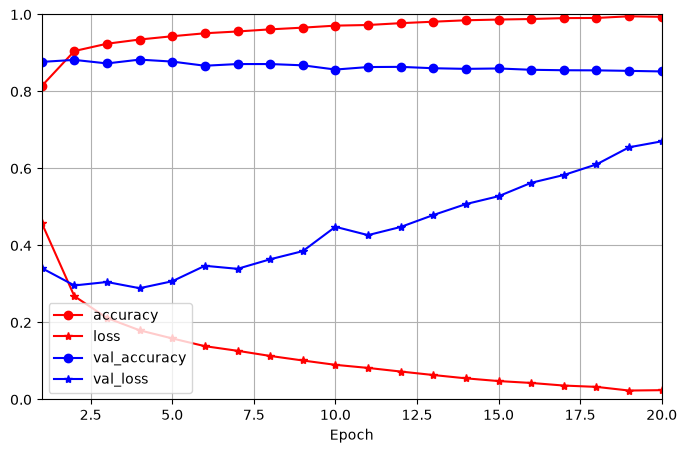

In [153]:
import matplotlib.pyplot as plt

def plot_learning_curves(history):
    plt.figure(figsize=(8, 5))
    for key, style in zip(history.history, ["r-o", "r-*", "b-o", "b-*"]):
        epochs = np.array(history.epoch)
        plt.plot(epochs + 1, history.history[key], style, label=key)

    plt.xlabel("Epoch")
    plt.axis([1, len(history.history["loss"]), 0.0, 1.0])
    plt.legend(loc="lower left")
    plt.grid()

plot_learning_curves(history)

In [154]:
model = get_model()
model.compile(
  optimizer="rmsprop",
  loss="binary_crossentropy",
  metrics=["accuracy"]
)
history = model.fit(
    X_train, y_train, 
    validation_data =(X_val, y_val), 
    epochs=3,
    batch_size=512
)

Epoch 1/3
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8129 - loss: 0.4614 - val_accuracy: 0.8570 - val_loss: 0.3635
Epoch 2/3
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9047 - loss: 0.2687 - val_accuracy: 0.8849 - val_loss: 0.2877
Epoch 3/3
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9239 - loss: 0.2105 - val_accuracy: 0.8851 - val_loss: 0.2855


## 2.6 Evaluate the Model

1. Use the `evaluate` method to evaluate the model on the test set.
2. What is the model's performance on the test set?

> You should get around 89% accuracy on the test set.


In [155]:
model.evaluate(X_test,y_test, batch_size=512)

30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8896 - loss: 0.2797 


[0.27967044711112976, 0.8895999789237976]

# 3. MNIST with a Deep MLP

This exercise is based on exercise 10 from Chapter 10 of *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* by Aurélien Géron. It contains more detailed instructions.


## 3.1 Load and Preprocess the MNIST Dataset

1. Use `keras.datasets.mnist.load_data()` to download the MNIST dataset.
2. Use the final 10,000 images of the training set as the validation set. This gives you 50,000 training images, 10,000 validation images, and 10,000 test images.
3. The pixel values are stored as integers from 0 to 255. Convert them to floats between 0.0 and 1.0 by dividing by 255.
4. Reshape the tensors so that they have rank 2 instead of rank 3.


In [156]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_train = x_train/255
x_test = x_test/255
assert x_train.shape == (60000, 28, 28)
assert x_test.shape == (10000, 28, 28)
assert y_train.shape == (60000,)
assert y_test.shape == (10000,)


In [157]:
print(x_train[0])

[[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.    

In [158]:
print(y_train[:10], "\n")
print(np.unique(y_train), "\n")
print(y_train.dtype)

[5 0 4 1 9 2 1 3 1 4] 

[0 1 2 3 4 5 6 7 8 9] 

uint8


In [159]:
x_val = x_train[-10_000:]
y_val = y_train[-10_000:]
x_train = x_train[:-10_000]
y_train = y_train[:-10_000]

x_train.shape

(50000, 28, 28)

In [160]:
y_train.shape

(50000,)

## 3.2 Build an MLP

1. Use the Sequential API to build a model with two hidden layers and one output layer.
2. Use the ReLU activation function for the hidden layers, with 300 and 100 units respectively. Choose the appropriate activation function and number of units for the output layer, given that this is a multi-class classification problem.
3. Create a function `get_model()` that returns this model.
4. The model should have 266,610 parameters when you display its summary.


In [161]:
# Build the MNIST model and define get_model()

def get_model():
  model = keras.Sequential()
  model.add(keras.layers.Flatten())
  model.add(keras.layers.Dense(300, activation="relu"))
  model.add(keras.layers.Dense(100, activation="relu"))
  model.add(keras.layers.Dense(10, activation="softmax"))
  
  return model

model = get_model()

## 3.3 Compile the Model

1. Create an SGD optimizer with a learning rate of 0.01.
2. Compile the model using the appropriate loss function for multi-class classification, taking into account that the labels are not one-hot encoded. Track the accuracy metric.


In [162]:
sgd = keras.optimizers.SGD(
  learning_rate=0.01
)

model.compile(
  optimizer=sgd,
  loss="sparse_categorical_crossentropy",
  metrics=["accuracy"]
)

## 3.4 Train the Model

1. Use a batch size of 256.
2. Train the model for a large number of epochs, but use the `EarlyStopping` callback to stop training when the validation accuracy has not improved for 5 epochs.
3. Also use the `ModelCheckpoint` callback to save the model with the best validation loss.
4. Use the `TensorBoard` callback to log the training process.


In [163]:
import tensorboard

callback_early = keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=5)
callback_modelcheckpoint = keras.callbacks.ModelCheckpoint(monitor='val_loss', filepath="./models/model.keras", save_best_only=True)
callback_tensorboard = keras.callbacks.TensorBoard()

history = model.fit(x_train, y_train, validation_data=(x_val, y_val),
  batch_size=256,
  epochs=20,
  callbacks=[callback_early, callback_modelcheckpoint, callback_tensorboard]
)

Epoch 1/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5954 - loss: 1.6694 - val_accuracy: 0.8074 - val_loss: 1.0590
Epoch 2/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8210 - loss: 0.8254 - val_accuracy: 0.8622 - val_loss: 0.6027
Epoch 3/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8570 - loss: 0.5702 - val_accuracy: 0.8861 - val_loss: 0.4641
Epoch 4/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8743 - loss: 0.4730 - val_accuracy: 0.8958 - val_loss: 0.4022
Epoch 5/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8848 - loss: 0.4212 - val_accuracy: 0.9054 - val_loss: 0.3644
Epoch 6/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8916 - loss: 0.3880 - val_accuracy: 0.9087 - val_loss: 0.3396
Epoch 7/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8976 - loss: 0.3643 - val_accuracy: 0.9129 - val_loss: 0.3223
Epoch 8/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9026 - loss: 0.3459 - val_accuracy: 0.

## 3.5 Evaluate the Model

1. Use the `evaluate` method to evaluate the model on the training, validation, and test sets.
2. Check that some of these results correspond to the output shown during training.


In [164]:
train_results = model.evaluate(
    x_train, y_train, batch_size=256, verbose=0, return_dict=True
)
val_results = model.evaluate(
    x_val, y_val, batch_size=256, verbose=0, return_dict=True
)
test_results = model.evaluate(
    x_test, y_test, batch_size=256, verbose=0, return_dict=True
)

for name, results in [
    ("Training", train_results),
    ("Validation", val_results),
    ("Test", test_results),
]:
    print(
        f"{name:10} | loss: {results['loss']:.4f}"
        f" | accuracy: {results['accuracy']:.4f}"
    )

Training   | loss: 0.2410 | accuracy: 0.9317
Validation | loss: 0.2251 | accuracy: 0.9364
Test       | loss: 0.2348 | accuracy: 0.9336


## 3.6 Try Different Learning Rates and Batch Sizes

1. Try different learning rates, for example `[0.01, 0.05, 0.1, 0.5]`, and batch sizes, for example `[64, 128, 256, 512]`. Observe how they affect the model's performance.
2. Check the learning curves in TensorBoard to inspect how training progressed.
3. Save all the different models and try to find the best one. Evaluate its performance on the test set.


In [165]:
from itertools import product

learning_rates = [0.01, 0.05, 0.1, .5]
batch_sizes = [64, 128, 256, 512]

for learning_r, batch_s in product(learning_rates, batch_sizes):
  sgd = keras.optimizers.SGD(
  learning_rate=learning_r
  )

  model.compile(
    optimizer=sgd,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
  )
  
  model.fit(x_train, y_train, validation_data=(x_val, y_val),
    batch_size=256,
    epochs=20,
    callbacks=[callback_early, callback_modelcheckpoint, callback_tensorboard]
    )

Epoch 1/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9316 - loss: 0.2395 - val_accuracy: 0.9383 - val_loss: 0.2225
Epoch 2/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9333 - loss: 0.2346 - val_accuracy: 0.9384 - val_loss: 0.2174
Epoch 3/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9347 - loss: 0.2300 - val_accuracy: 0.9403 - val_loss: 0.2136
Epoch 4/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9362 - loss: 0.2257 - val_accuracy: 0.9414 - val_loss: 0.2109
Epoch 5/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9372 - loss: 0.2216 - val_accuracy: 0.9432 - val_loss: 0.2078
Epoch 6/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9378 - loss: 0.2176 - val_accuracy: 0.9434 - val_loss: 0.2028
Epoch 7/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9394 - loss: 0.2136 - val_accuracy: 0.9450 - val_loss: 0.1999
Epoch 8/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9407 - loss: 0.2100 - val_accuracy: 0.

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,612 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

flatten {'name': 'flatten', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'data_format': 'channels_last'}
dense_6 {'name': 'dense_6', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'units': 300, 'activation': 'relu', 'use_bias': True, 'kernel_initializer': {'module': 'keras.initializers', 'class_name': 'GlorotUniform', 'config': {'seed': None, 'input_axes': None, 'output_axes': None}, 'registered_name': None}, 'bias_initializer': {'module': 'keras.initializers', 'class_name': 'Zeros', 'config': {}, 'registered_name': None}, 'kernel_regularizer': None, 'bias_regularizer': None, 'kernel_constraint': None, 'bias_constraint': None, 'quantization_config': None}
dense_7 {'name': 'dense_7', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}

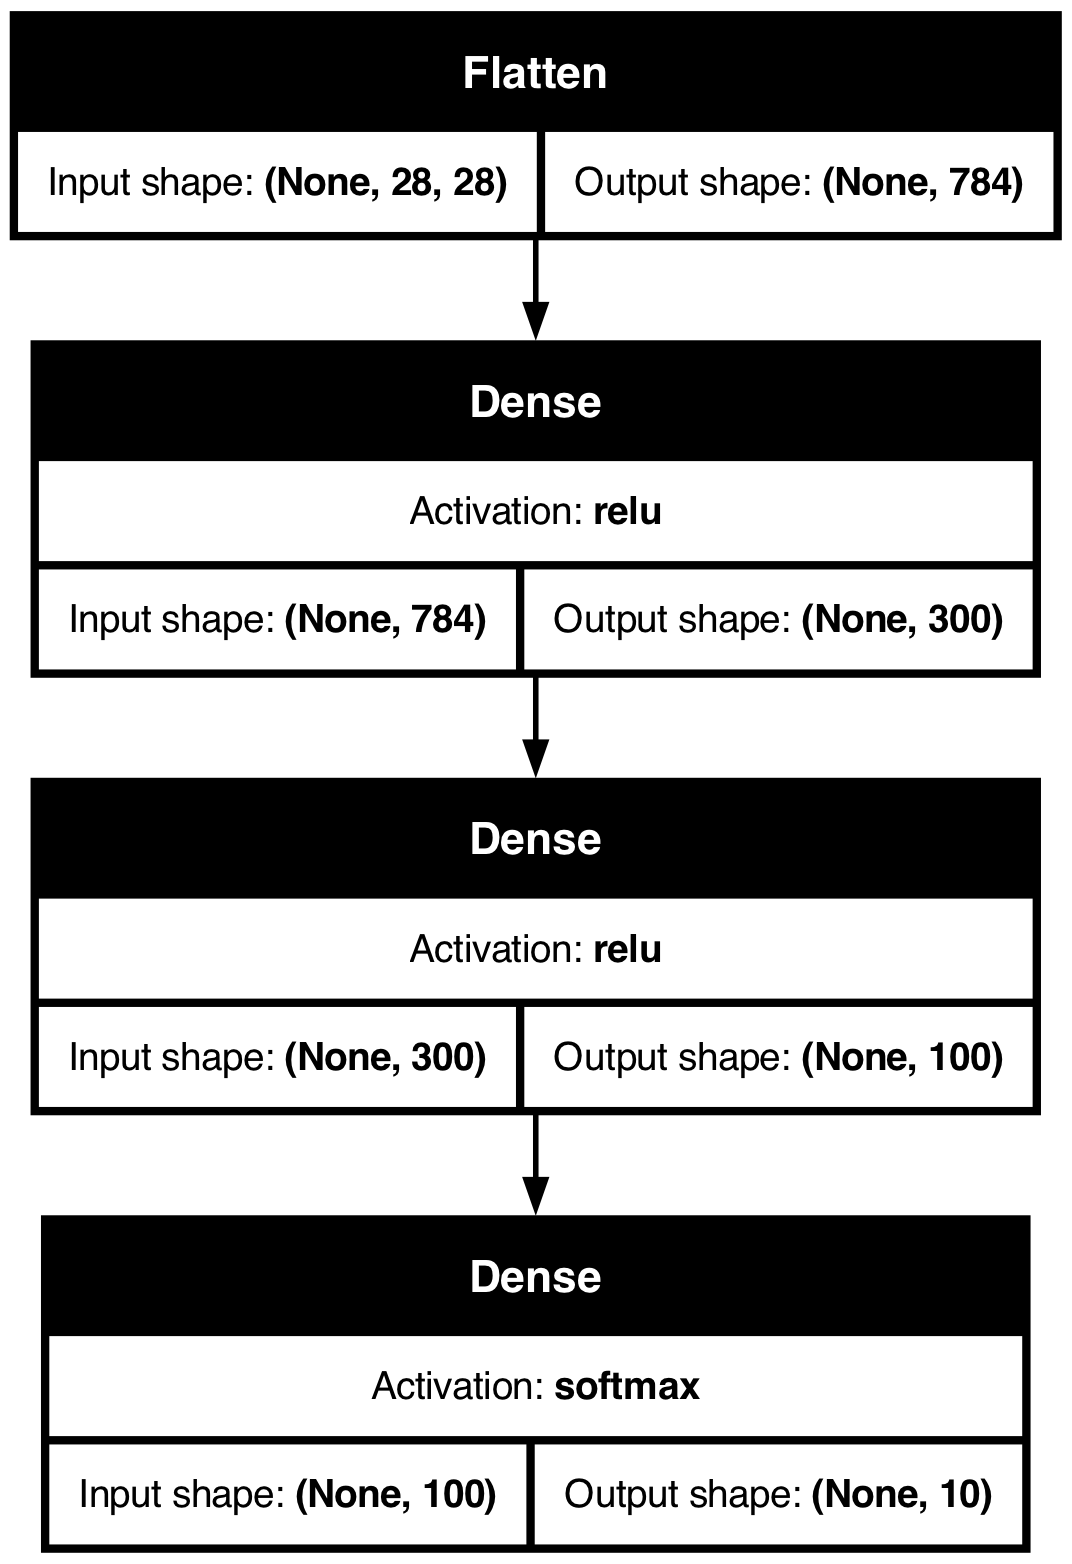

In [166]:
import pydot

best_model = keras.saving.load_model(filepath='./models/model.keras')

best_model.summary()
for layer in best_model.layers:
    print(layer.name, layer.get_config())
    
    dense = best_model.layers[1]
weights, biases = dense.get_weights()

keras.utils.plot_model(
    best_model,
    to_file="model.png",
    show_shapes=True,
    show_layer_activations=True,
)